In [8]:
#final

import os
import pandas as pd
import numpy as np
from scipy.stats import zscore, pearsonr, ttest_ind
from statsmodels.stats.multitest import multipletests

# --- 1. CONFIGURAÇÕES E CARREGAMENTO ---
metadata_path = r'.\ArquivosNew\GordonReligious\LEiDA_results\metadata.csv'
base_ts_path = r'.\ArquivosNew\GordonReligious\LEiDA_results\time_series'
labels_path = r'.\ArquivosNew\GordonReligious\LEiDA_results\rois_labels.txt'

df_metadata = pd.read_csv(metadata_path)
valores_unicos = df_metadata['condition'].unique()
g_a_nome, g_b_nome = valores_unicos[0], valores_unicos[1]

with open(labels_path, 'r') as f:
    roi_names = [line.strip() for line in f.readlines() if line.strip() and not line.startswith('[source')]

# --- 2. FUNÇÕES DE APOIO ---
def load_all_data(metadata_df, base_path):
    all_data, data_a, data_b = [], [], []
    for _, row in metadata_df.iterrows():
        sub_id, cond = str(row['subject_id']), row['condition']
        file_path = os.path.join(base_path, sub_id, 'tseries.csv')
        if os.path.exists(file_path):
            ts = pd.read_csv(file_path, header=None).values.T
            all_data.append(ts)
            if cond == g_a_nome: data_a.append(ts)
            else: data_b.append(ts)
    return np.array(all_data), np.array(data_a), np.array(data_b)

def compute_isc(data):
    n_subs, n_time, n_rois = data.shape
    z_data = np.array([zscore(d, axis=0) for d in data])
    isc_results = np.zeros((n_subs, n_rois))
    for s in range(n_subs):
        sub_ts = z_data[s]
        others_mean = np.delete(z_data, s, axis=0).mean(axis=0)
        for r in range(n_rois):
            if np.std(sub_ts[:, r]) == 0 or np.std(others_mean[:, r]) == 0:
                isc_results[s, r] = 0
            else:
                res, _ = pearsonr(sub_ts[:, r], others_mean[:, r])
                isc_results[s, r] = res
    return isc_results

# --- 3. EXECUÇÃO ---
print("Processando dados...")
group_all, group_a, group_b = load_all_data(df_metadata, base_ts_path)

# Cálculo de ISC para os grupos e para o Total (N=6)
isc_total = compute_isc(group_all)
isc_a = compute_isc(group_a)
isc_b = compute_isc(group_b)

# Estatística de comparação entre Grupos
t_stats, p_values = ttest_ind(isc_a, isc_b, axis=0)
_, pvals_fdr, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')

print("\n--- DEBUG TAMANHOS ---")
print("roi_names:", len(roi_names))
print("isc_total mean:", np.mean(isc_total, axis=0).shape)
print("isc_a mean:", np.mean(isc_a, axis=0).shape)
print("isc_b mean:", np.mean(isc_b, axis=0).shape)
print("t_stats:", t_stats.shape)
print("p_values:", p_values.shape)
print("pvals_fdr:", pvals_fdr.shape)

# --- 4. ORGANIZAÇÃO FINAL ---
df_final = pd.DataFrame({
    'ROI': roi_names,
    'ISC_Geral_N6': np.mean(isc_total, axis=0), # Média de sincronia de todos os sujeitos
    f'ISC_Media_{g_a_nome}': np.mean(isc_a, axis=0),
    f'ISC_Media_{g_b_nome}': np.mean(isc_b, axis=0),
    'T_stat_A_vs_B': t_stats,
    'p_uncorrected': p_values,
    'p_FDR': pvals_fdr
}).sort_values(by='ISC_Geral_N6', ascending=False) # Ordenado pelas ROIs que mais sincronizaram no total

df_final.to_csv('resultados_ISC_completo_Geral.csv', index=False)

print("\n✅ Arquivo 'resultados_ISC_completo_Geral.csv' gerado!")
print("\nTop 5 ROIs com maior Sincronia Geral (N=6):")
print(df_final[['ROI', 'ISC_Geral_N6']].head(5))

Processando dados...

--- DEBUG TAMANHOS ---
roi_names: 333
isc_total mean: (333,)
isc_a mean: (333,)
isc_b mean: (333,)
t_stats: (333,)
p_values: (333,)
pvals_fdr: (333,)

✅ Arquivo 'resultados_ISC_completo_Geral.csv' gerado!

Top 5 ROIs com maior Sincronia Geral (N=6):
              ROI  ISC_Geral_N6
130        L__131      0.511877
298  R_Visual_299      0.498043
138        L__139      0.494280
140        L__141      0.493477
7            L__8      0.485018


~\AppData\Local\Temp\ipykernel_22124\2884577617.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_isc, x='ISC_Geral_N6', y='ROI', palette='magma')


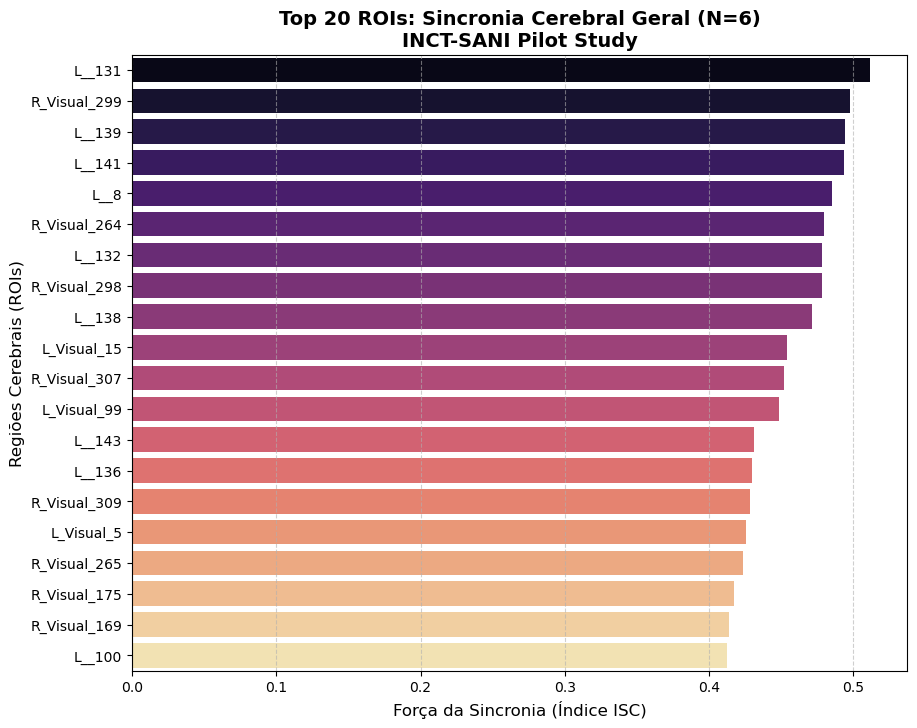

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Carregar os resultados que acabamos de salvar
df_results = pd.read_csv('resultados_ISC_completo_Geral.csv')

# Selecionar as 20 ROIs com maior ISC Geral
top_20_isc = df_results.nlargest(20, 'ISC_Geral_N6')

plt.figure(figsize=(10, 8))
sns.barplot(data=top_20_isc, x='ISC_Geral_N6', y='ROI', palette='magma')

plt.title('Top 20 ROIs: Sincronia Cerebral Geral (N=6)\nINCT-SANI Pilot Study', fontsize=14, weight='bold')
plt.xlabel('Força da Sincronia (Índice ISC)', fontsize=12)
plt.ylabel('Regiões Cerebrais (ROIs)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.savefig('grafico_barras_ISC_geral.png', dpi=300, bbox_inches='tight')
plt.show()

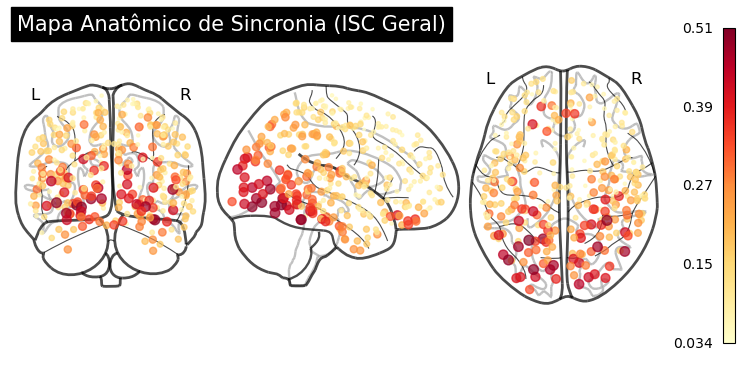

In [12]:
from nilearn import plotting
import numpy as np

# Carregar coordenadas
coords_df = pd.read_csv(r'.\ArquivosNew\GordonReligious\LEiDA_results\rois_coordinates.csv')
coords = coords_df.values

# Pegar os valores de ISC Geral na ordem correta das ROIs
# Garantimos que a ordem do CSV de resultados bate com a ordem das coordenadas
df_ordered = df_results.set_index('ROI').reindex(roi_names).reset_index()
isc_values = df_ordered['ISC_Geral_N6'].values

# Gerar o Glass Brain
display = plotting.plot_markers(
    node_values=isc_values, 
    node_coords=coords, 
    node_cmap='YlOrRd', # Amarelo para Laranja/Vermelho
    display_mode='ortho',
    node_size=isc_values * 100, # O tamanho da "bola" escala com a sincronia
    title="Mapa Anatômico de Sincronia (ISC Geral)"
)

display.savefig('glass_brain_ISC.png', dpi=300)

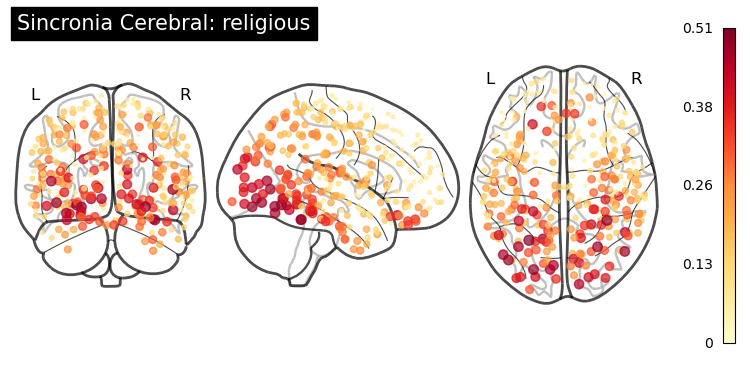

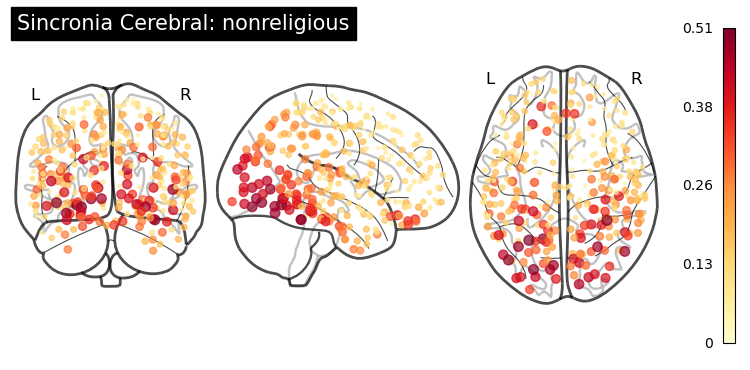

In [13]:
from nilearn import plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Carregar coordenadas (164 ROIs)
coords_df = pd.read_csv(r'.\ArquivosNew\GordonReligious\LEiDA_results\rois_coordinates.csv')
coords = coords_df.values 

# 2. Carregar resultados e garantir a ordem original das ROIs
df_results = pd.read_csv('resultados_ISC_completo_Geral.csv')

# Usamos os nomes detectados anteriormente: g_a_nome e g_b_nome
col_a = f'ISC_Media_{g_a_nome}'
col_b = f'ISC_Media_{g_b_nome}'

# Reordenar para bater com as coordenadas
df_ordered = df_results.set_index('ROI').reindex(roi_names).reset_index()
isc_a = df_ordered[col_a].values
isc_b = df_ordered[col_b].values

# 3. Definir um valor máximo comum para a escala (ajuda na comparação visual)
vmax = max(isc_a.max(), isc_b.max())

# --- MAPA GRUPO A (RELIGIOSO) ---
display_a = plotting.plot_markers(
    node_values=isc_a, 
    node_coords=coords, 
    node_cmap='YlOrRd', 
    display_mode='ortho',
    node_size=isc_a * 100, # Tamanho da esfera proporcional à sincronia
    title=f"Sincronia Cerebral: {g_a_nome}",
    colorbar=True,
    node_vmin=0,
    node_vmax=vmax
)
display_a.savefig(f'glass_brain_ISC_{g_a_nome}.png', dpi=300)

# --- MAPA GRUPO B (NÃO-RELIGIOSO) ---
display_b = plotting.plot_markers(
    node_values=isc_b, 
    node_coords=coords, 
    node_cmap='YlOrRd', 
    display_mode='ortho',
    node_size=isc_b * 100, 
    title=f"Sincronia Cerebral: {g_b_nome}",
    colorbar=True,
    node_vmin=0,
    node_vmax=vmax
)
display_b.savefig(f'glass_brain_ISC_{g_b_nome}.png', dpi=300)

plotting.show()

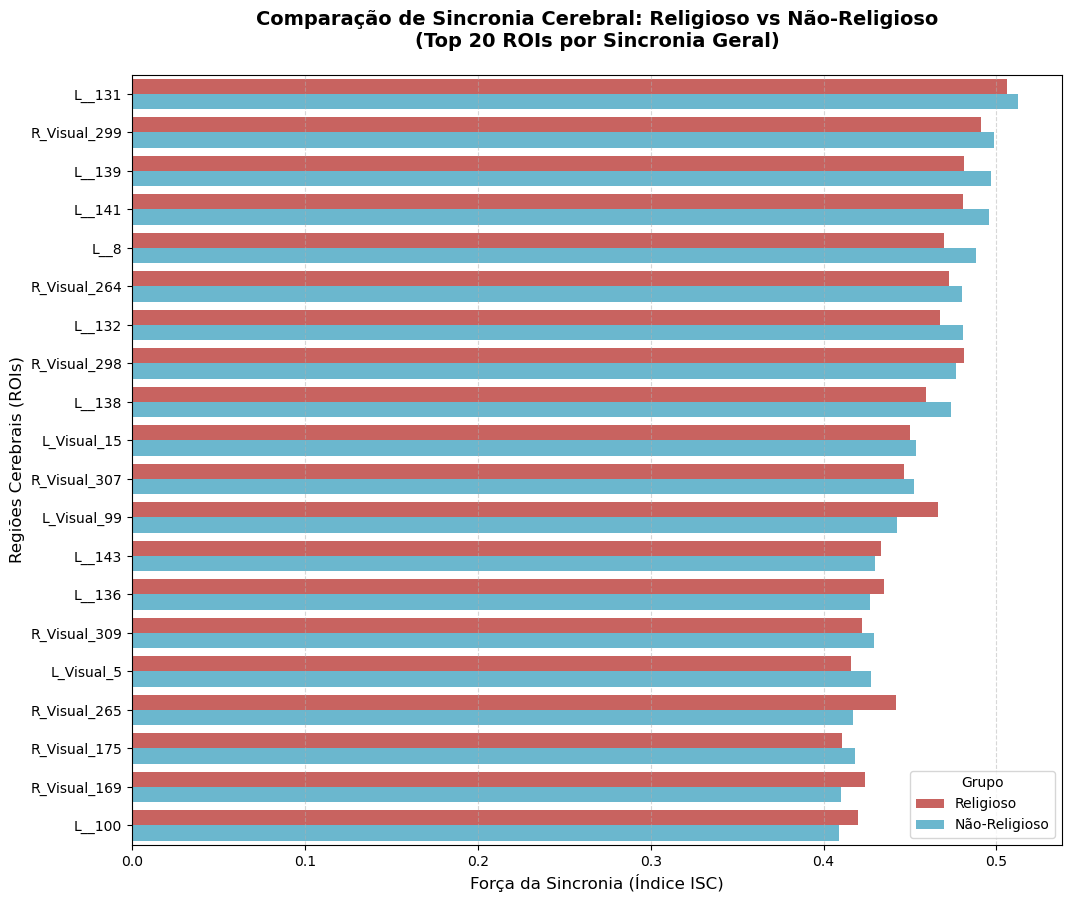

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Carregar os resultados
df_results = pd.read_csv('resultados_ISC_completo_Geral.csv')

# 2. Identificar os nomes das colunas de grupo (ajusta automaticamente caso mude o nome)
col_rel = [c for c in df_results.columns if 'Media' in c and 'rel' in c.lower()][0]
col_non = [c for c in df_results.columns if 'Media' in c and ('non' in c.lower() or 'nao' in c.lower())][0]

# 3. Selecionar as 20 ROIs com maior ISC GERAL para manter o foco nas áreas mais relevantes
top_20_rois = df_results.nlargest(20, 'ISC_Geral_N6')

# 4. Transformar o dado para o formato "long-form" (necessário para o Seaborn fazer o 'hue')
df_plot = top_20_rois.melt(id_vars=['ROI'], 
                           value_vars=[col_rel, col_non], 
                           var_name='Grupo', 
                           value_name='ISC')

# Ajustar nomes para a legenda ficar bonita
df_plot['Grupo'] = df_plot['Grupo'].replace({col_rel: 'Religioso', col_non: 'Não-Religioso'})

# 5. Criar o gráfico
plt.figure(figsize=(12, 10))
sns.barplot(data=df_plot, y='ROI', x='ISC', hue='Grupo', palette=['#d9534f', '#5bc0de'])

# Customização
plt.title('Comparação de Sincronia Cerebral: Religioso vs Não-Religioso\n(Top 20 ROIs por Sincronia Geral)', 
          fontsize=14, weight='bold', pad=20)
plt.xlabel('Força da Sincronia (Índice ISC)', fontsize=12)
plt.ylabel('Regiões Cerebrais (ROIs)', fontsize=12)
plt.legend(title='Grupo', frameon=True)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# 6. Salvar e Mostrar
plt.savefig('comparacao_ISC_grupos_top20.png', dpi=300, bbox_inches='tight')
plt.show()

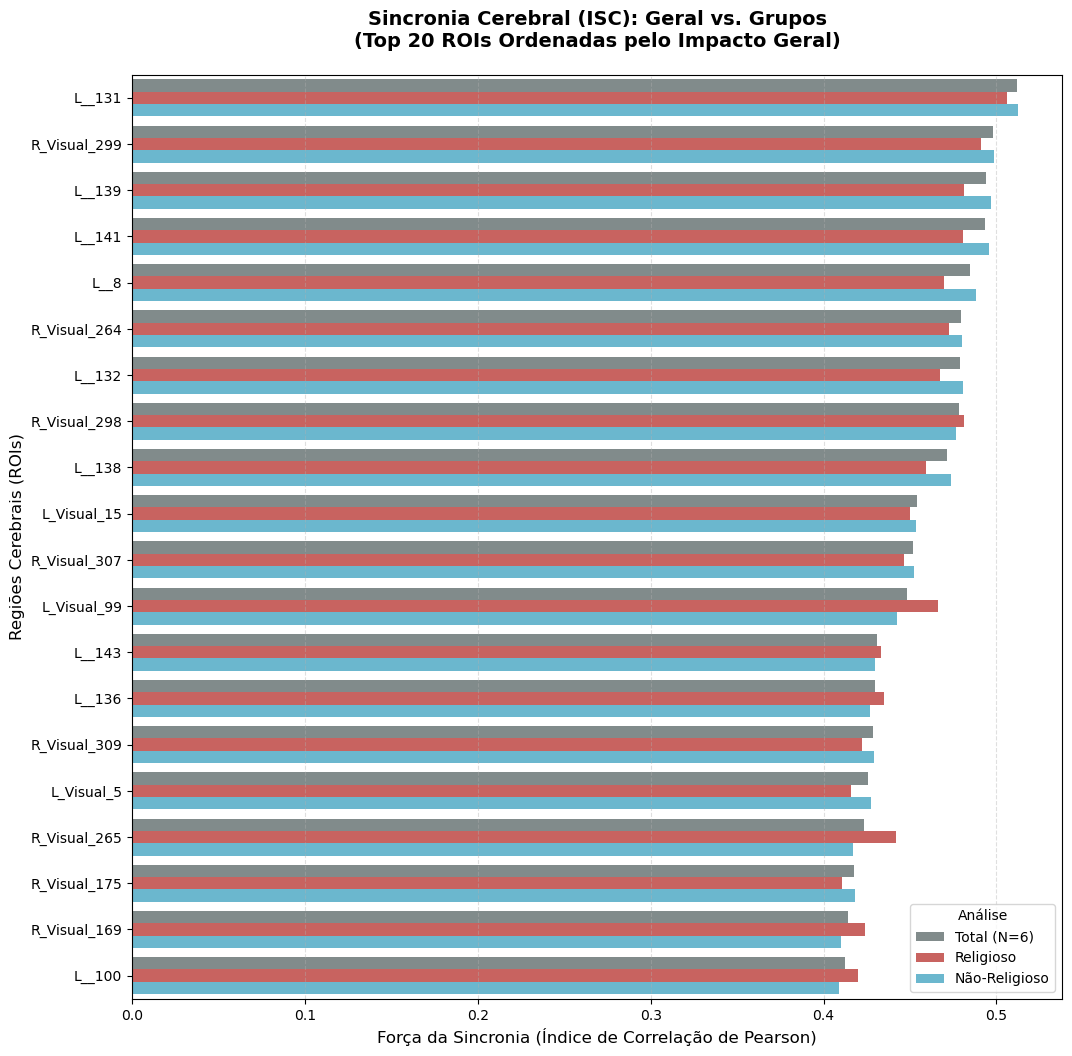

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Carregar os resultados
df_results = pd.read_csv('resultados_ISC_completo_Geral.csv')

# 2. Identificar as colunas dinamicamente
col_geral = 'ISC_Geral_N6'
col_rel = [c for c in df_results.columns if 'Media' in c and 'rel' in c.lower()][0]
col_non = [c for c in df_results.columns if 'Media' in c and ('non' in c.lower() or 'nao' in c.lower())][0]

# 3. Selecionar as 20 ROIs com maior sincronia GERAL
top_20_rois = df_results.nlargest(20, col_geral)

# 4. "Derreter" (melt) o dataframe para o formato longo (exigido pelo Seaborn)
# Agora incluímos as três colunas de valor
df_plot = top_20_rois.melt(id_vars=['ROI'], 
                           value_vars=[col_geral, col_rel, col_non], 
                           var_name='Metrica', 
                           value_name='ISC')

# Ajustar nomes para a legenda ficar profissional
df_plot['Metrica'] = df_plot['Metrica'].replace({
    col_geral: 'Total (N=6)', 
    col_rel: 'Religioso', 
    col_non: 'Não-Religioso'
})

# 5. Criar o gráfico
plt.figure(figsize=(12, 12))
# Definindo cores: Cinza para o Geral, Vermelho para Religioso, Azul para Não-Religioso
cores = ['#7f8c8d', '#d9534f', '#5bc0de']

sns.barplot(data=df_plot, y='ROI', x='ISC', hue='Metrica', palette=cores)

# Customização técnica
plt.title('Sincronia Cerebral (ISC): Geral vs. Grupos\n(Top 20 ROIs Ordenadas pelo Impacto Geral)', 
          fontsize=14, weight='bold', pad=20)
plt.xlabel('Força da Sincronia (Índice de Correlação de Pearson)', fontsize=12)
plt.ylabel('Regiões Cerebrais (ROIs)', fontsize=12)
plt.legend(title='Análise', frameon=True, loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.4)

# 6. Salvar e Mostrar
plt.savefig('comparacao_ISC_triplo_geral_grupos.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
#temporal

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr

# --- CONFIGURAÇÃO DA JANELA ---
window_size = 20  # Tamanho da janela (ex: 20 volumes/pontos de tempo)
step_size = 1     # Passo de deslocamento (1 ponto por vez para suavidade)

def compute_dynamic_isc(data, window, step):
    """
    Calcula ISC em janelas deslizantes.
    data: array (sujeitos, tempo, ROIs)
    """
    n_subs, n_time, n_rois = data.shape
    z_data = np.array([zscore(d, axis=0) for d in data])
    
    # Definir os centros das janelas para o eixo X do gráfico
    time_points = range(0, n_time - window, step)
    dynamic_isc = np.zeros((len(time_points), n_rois))
    
    for i, start in enumerate(time_points):
        end = start + window
        # Recorta o trecho do tempo para todos os sujeitos
        window_data = z_data[:, start:end, :]
        
        # Calcula ISC média para esta janela (simplificado: média de todos os pares)
        roi_isc = np.zeros(n_rois)
        for r in range(n_rois):
            corrs = []
            for s in range(n_subs):
                sub_ts = window_data[s, :, r]
                others_mean = np.delete(window_data, s, axis=0).mean(axis=0)[:, r]
                r_val, _ = pearsonr(sub_ts, others_mean)
                corrs.append(r_val)
            roi_isc[r] = np.mean(corrs)
        
        dynamic_isc[i, :] = roi_isc
        
    return list(time_points), dynamic_isc

# --- EXECUÇÃO ---
# group_all foi carregado no código anterior (N=6)
times, d_isc = compute_dynamic_isc(group_all, window_size, step_size)

# Criar DataFrame para a ISC Dinâmica Geral
df_dynamic = pd.DataFrame(d_isc, index=times, columns=roi_names)
# Adicionar coluna de média geral de todas as ROIs no tempo
df_dynamic['MEDIA_GLOBAL'] = df_dynamic.mean(axis=1)

# --- VISUALIZAÇÃO ---
plt.figure(figsize=(12, 6))
plt.plot(df_dynamic.index, df_dynamic['MEDIA_GLOBAL'], color='black', linewidth=2, label='Sincronia Global')

# Opcional: Plotar as 3 ROIs que mais sincronizaram para ver a variação delas
top_rois = df_final.nlargest(3, 'ISC_Geral_N6')['ROI'].values
for roi in top_rois:
    plt.plot(df_dynamic.index, df_dynamic[roi], alpha=0.5, label=f'ROI: {roi}')

plt.title('ISC Dinâmica: Como a Sincronia Cerebral Muda ao Longo do Tempo')
plt.xlabel('Tempo (Pontos de Tempo)')
plt.ylabel('Sincronia (r de Pearson)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Salvar para análise detalhada
df_dynamic.to_csv('isc_dinamica_ao_longo_do_tempo.csv')

KeyboardInterrupt: 

In [13]:
df_dynamic

,"networks.DefaultMode.MPFC (1,55,-3)","networks.DefaultMode.LP (L) (-39,-77,33)","networks.DefaultMode.LP (R) (47,-67,29)","networks.DefaultMode.PCC (1,-61,38)","networks.SensoriMotor.Lateral (L) (-55,-12,29)","networks.SensoriMotor.Lateral (R) (56,-10,29)","networks.SensoriMotor.Superior (0,-31,67)","networks.Visual.Medial (2,-79,12)","networks.Visual.Occipital (0,-93,-4)","networks.Visual.Lateral (L) (-37,-79,10)",...,atlas.Cereb10 r (Cerebelum 10 Right),atlas.Ver12 (Vermis 1 2),atlas.Ver3 (Vermis 3),atlas.Ver45 (Vermis 4 5),atlas.Ver6 (Vermis 6),atlas.Ver7 (Vermis 7),atlas.Ver8 (Vermis 8),atlas.Ver9 (Vermis 9),atlas.Ver10 (Vermis 10),MEDIA_GLOBAL
0,-0.133085,0.043222,0.145587,-0.200763,0.242521,0.011347,-0.290250,0.105619,-0.332730,-0.230955,...,0.021767,0.049122,0.040167,-0.446252,0.301712,0.075869,0.223679,0.182668,-0.076671,0.013177
1,-0.128560,0.001946,0.131797,-0.216172,0.239200,0.011952,-0.227950,0.089106,-0.330683,-0.217915,...,0.004903,0.030428,0.023192,-0.468193,0.289289,0.115691,0.235873,0.165134,-0.085645,0.011635
2,-0.169887,0.005867,0.134116,-0.204599,0.242241,0.035130,-0.236415,0.094240,-0.213415,-0.126411,...,0.028514,0.054053,-0.016348,-0.529903,0.268394,0.074760,0.248130,0.211875,-0.033604,0.016875
3,-0.146000,-0.006402,0.148183,-0.231315,0.248443,-0.009990,-0.232919,0.108058,-0.243180,-0.086777,...,0.038887,0.060584,-0.001818,-0.539604,0.249307,0.075599,0.244889,0.216849,-0.023002,0.013886
4,-0.129690,-0.006447,0.142250,-0.224836,0.243382,-0.052142,-0.204095,0.135966,-0.163119,-0.091033,...,0.062726,0.059915,-0.001025,-0.538563,0.304142,0.074359,0.248526,0.205992,-0.049863,0.013409
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,0.091193,0.066451,0.150736,0.178734,0.276050,0.128142,0.073903,0.071446,0.017686,0.147965,...,0.044434,0.275887,0.069119,0.161791,0.290761,0.246630,0.124449,0.255979,0.139225,0.119932
142,0.096621,0.081904,0.184716,0.178906,0.212637,0.094940,0.100841,0.133489,0.036402,0.205676,...,0.032385,0.255572,0.023932,0.145655,0.273451,0.259955,0.173565,0.249670,0.067414,0.118444
143,0.096978,0.064333,0.182900,0.178855,0.219331,0.093739,0.093154,0.137534,0.025842,0.211026,...,0.120002,0.265411,0.104422,0.174934,0.276034,0.306631,0.194874,0.253429,0.095981,0.125321
144,0.068961,0.075178,0.189928,0.123727,0.201303,0.090787,0.090028,0.135899,-0.015591,0.211021,...,0.115110,0.250824,0.100804,0.178925,0.276166,0.289532,0.196171,0.248692,0.091090,0.130126


Calculando ISC Dinâmica (Janela=30)...


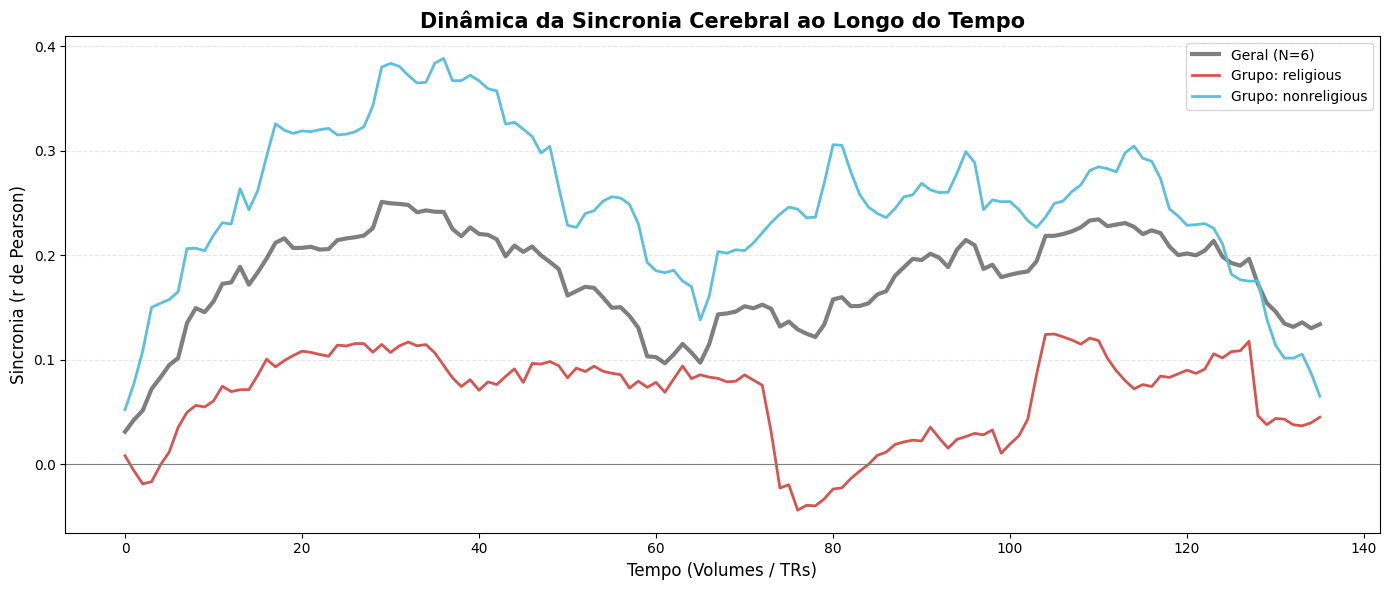

✅ Análise dinâmica concluída e salva!


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr

# --- 1. CONFIGURAÇÃO DA JANELA ---
window_size = 30  
step_size = 1     

def sliding_window_isc(data):
    """Calcula ISC dinâmica para um conjunto de dados (sujeitos, tempo, rois)"""
    if len(data.shape) < 3: return [] # Evita erro se o grupo estiver vazio
    
    n_subs, n_time, n_rois = data.shape
    z_data = np.array([zscore(d, axis=0) for d in data])
    
    time_points = range(0, n_time - window_size, step_size)
    isc_over_time = []
    
    for start in time_points:
        end = start + window_size
        window_chunk = z_data[:, start:end, :]
        
        window_corrs = []
        for r in range(n_rois):
            sub_corrs = []
            for s in range(n_subs):
                sub_ts = window_chunk[s, :, r]
                others_mean = np.delete(window_chunk, s, axis=0).mean(axis=0)[:, r]
                # Pearson r
                r_val, _ = pearsonr(sub_ts, others_mean)
                sub_corrs.append(r_val)
            window_corrs.append(np.mean(sub_corrs))
        
        isc_over_time.append(np.mean(window_corrs))
        
    return list(time_points), isc_over_time

# --- 2. EXECUÇÃO DA ANÁLISE ---
# Usando as variáveis carregadas nos blocos anteriores (group_all, group_a, group_b)
print(f"Calculando ISC Dinâmica (Janela={window_size})...")

times, disc_geral = sliding_window_isc(group_all)
_, disc_a = sliding_window_isc(group_a)
_, disc_b = sliding_window_isc(group_b)

# --- 3. VISUALIZAÇÃO TEMPORAL ---
plt.figure(figsize=(14, 6))

# Plotagem das curvas usando os nomes dinâmicos (g_a_nome e g_b_nome definidos antes)
plt.plot(times, disc_geral, label='Geral (N=6)', color='black', linewidth=3, alpha=0.5)
plt.plot(times, disc_a, label=f'Grupo: {g_a_nome}', color='#d9534f', linewidth=2)
plt.plot(times, disc_b, label=f'Grupo: {g_b_nome}', color='#5bc0de', linewidth=2)

# Customização técnica
plt.title('Dinâmica da Sincronia Cerebral ao Longo do Tempo', fontsize=15, weight='bold')
plt.xlabel('Tempo (Volumes / TRs)', fontsize=12)
plt.ylabel('Sincronia (r de Pearson)', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.axhline(0, color='grey', linewidth=0.8)

plt.tight_layout()
plt.savefig('ISC_Dinamica_Comparativa_Final.png', dpi=300)
plt.show()

# --- 4. SALVAR RESULTADOS ---
df_temp = pd.DataFrame({
    'Tempo_Inicio': times,
    'ISC_Geral': disc_geral,
    f'ISC_{g_a_nome}': disc_a,
    f'ISC_{g_b_nome}': disc_b
})
df_temp.to_csv('tabela_isc_dinamica_final.csv', index=False)
print("✅ Análise dinâmica concluída e salva!")

In [18]:
import pandas as pd

def sincronizar_com_video(times, disc_geral, disc_a, disc_b, tr=2.2, window_size=30):
    """
    Sincroniza os índices da janela deslizante com o tempo real do vídeo.
    
    times: lista de índices de início das janelas
    disc_geral, disc_a, disc_b: listas com os valores de ISC calculados
    tr: Time of Repetition (2.2s)
    window_size: tamanho da janela usado no cálculo anterior
    """
    
    # Criar o DataFrame base
    df = pd.DataFrame({
        'Indice_Inicio': times,
        'ISC_Geral': disc_geral,
        f'ISC_{g_a_nome}': disc_a,
        f'ISC_{g_b_nome}': disc_b
    })
    
    # 1. Calcular o Centro da Janela (é onde a correlação é mais representativa)
    # Ex: Se a janela vai de 0 a 30, o resultado representa o ponto 15.
    df['Indice_Centro'] = df['Indice_Inicio'] + (window_size / 2)
    
    # 2. Converter para Segundos Reais
    df['Tempo_Segundos'] = df['Indice_Centro'] * tr
    
    # 3. Criar formato MM:SS para conferir no vídeo
    def converter_para_mmss(seg):
        m = int(seg // 60)
        s = int(seg % 60)
        return f"{m:02d}:{s:02d}"
    
    df['Tempo_Video_MMSS'] = df['Tempo_Segundos'].apply(converter_para_mmss)
    
    # Reordenar para facilitar a leitura no Excel/CSV
    cols = ['Indice_Inicio', 'Indice_Centro', 'Tempo_Video_MMSS', 'Tempo_Segundos', 
            'ISC_Geral', f'ISC_{g_a_nome}', f'ISC_{g_b_nome}']
    
    return df[cols]

# --- COMO USAR APÓS O CÁLCULO ---
# Supondo que você acabou de rodar: times, disc_geral... = sliding_window_isc(...)

tr_fixo = 2.2
janela_usada = 30 # Altere aqui se mudar no sliding_window_isc

df_cronograma = sincronizar_com_video(times, disc_geral, disc_a, disc_b, 
                                      tr=tr_fixo, 
                                      window_size=janela_usada)

# Salvar a versão final
df_cronograma.to_csv('isc_dinamica_sincronizada_video.csv', index=False)

print(f"✅ Tabela sincronizada com TR={tr_fixo} e Janela={janela_usada}")
print(df_cronograma[['Tempo_Video_MMSS', 'ISC_Geral']].head())

✅ Tabela sincronizada com TR=2.2 e Janela=30
  Tempo_Video_MMSS  ISC_Geral
0            00:33   0.030899
1            00:35   0.042198
2            00:37   0.051226
3            00:39   0.071830
4            00:41   0.082869


In [19]:
Código: ISC Dinâmica por ROI + Sincronização de Tempo

SyntaxError: invalid syntax (1314726463.py, line 1)

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore, pearsonr

# --- 1. CONFIGURAÇÕES ---
TR = 2.2           # Seu TR
window_size = 30    # Tamanho da janela (em volumes/TRs)
step_size = 1       # Deslocamento da janela

def compute_dynamic_isc_full(data, roi_names):
    """Calcula ISC dinâmica para cada ROI individualmente"""
    n_subs, n_time, n_rois = data.shape
    z_data = np.array([zscore(d, axis=0) for d in data])
    
    time_indices = range(0, n_time - window_size, step_size)
    results_list = []
    
    for start in time_indices:
        end = start + window_size
        window_chunk = z_data[:, start:end, :]
        
        # Calcular o tempo real (centro da janela)
        centro_tr = start + (window_size / 2)
        tempo_seg = centro_tr * TR
        minutos = int(tempo_seg // 60)
        segundos = int(tempo_seg % 60)
        tempo_mmss = f"{minutos:02d}:{segundos:02d}"
        
        # Dicionário para armazenar os dados desta janela
        row = {
            'Indice_Inicio': start,
            'Tempo_Video_MMSS': tempo_mmss,
            'Tempo_Segundos': tempo_seg
        }
        
        # Calcular ISC para cada ROI nesta janela
        rois_values = []
        for r in range(n_rois):
            sub_corrs = []
            for s in range(n_subs):
                sub_ts = window_chunk[s, :, r]
                others_mean = np.delete(window_chunk, s, axis=0).mean(axis=0)[:, r]
                r_val, _ = pearsonr(sub_ts, others_mean)
                sub_corrs.append(r_val)
            
            roi_avg = np.mean(sub_corrs)
            row[roi_names[r]] = roi_avg
            rois_values.append(roi_avg)
            
        # Adiciona a média global desta janela (Média de todas as ROIs)
        row['MEDIA_GLOBAL_JANELA'] = np.mean(rois_values)
        results_list.append(row)
        
    return pd.DataFrame(results_list)

# --- 2. EXECUÇÃO ---
print(f"Calculando dISC por ROI (N={len(roi_names)} áreas)...")

# Gerar para o Geral, Religioso e Não-Religioso
# (Assumindo que group_all, group_a e group_b estão na memória)

df_dyn_geral = compute_dynamic_isc_full(group_all, roi_names)
df_dyn_a = compute_dynamic_isc_full(group_a, roi_names)
df_dyn_b = compute_dynamic_isc_full(group_b, roi_names)

# --- 3. SALVAR ---
df_dyn_geral.to_csv('isc_dinamica_TODAS_ROIS_geral.csv', index=False)
df_dyn_a.to_csv(f'isc_dinamica_TODAS_ROIS_{g_a_nome}.csv', index=False)
df_dyn_b.to_csv(f'isc_dinamica_TODAS_ROIS_{g_b_nome}.csv', index=False)

print("✅ Planilhas detalhadas geradas!")
print(f"Exemplo da ROI '{roi_names[0]}' no tempo {df_dyn_geral['Tempo_Video_MMSS'].iloc[0]}:")
print(df_dyn_geral[['Tempo_Video_MMSS', roi_names[0], 'MEDIA_GLOBAL_JANELA']].head())

Calculando dISC por ROI (N=164 áreas)...
✅ Planilhas detalhadas geradas!
Exemplo da ROI 'networks.DefaultMode.MPFC (1,55,-3)' no tempo 00:33:
  Tempo_Video_MMSS  networks.DefaultMode.MPFC (1,55,-3)  MEDIA_GLOBAL_JANELA
0            00:33                            -0.091935             0.030899
1            00:35                            -0.111620             0.042198
2            00:37                            -0.104370             0.051226
3            00:39                            -0.061022             0.071830
4            00:41                            -0.083729             0.082869


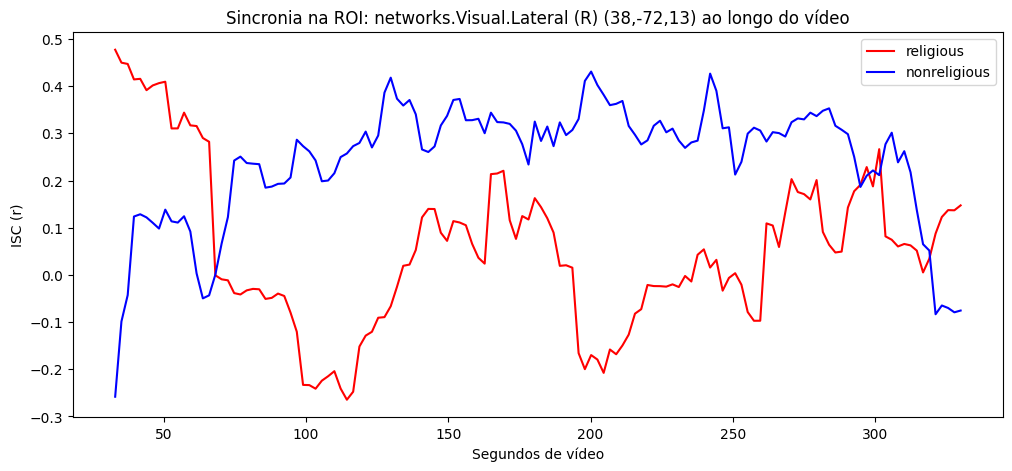

In [21]:
roi_alvo = roi_names[10] # Escolha o índice da ROI que te interessa

plt.figure(figsize=(12, 5))
plt.plot(df_dyn_a['Tempo_Segundos'], df_dyn_a[roi_alvo], label=f'{g_a_nome}', color='red')
plt.plot(df_dyn_b['Tempo_Segundos'], df_dyn_b[roi_alvo], label=f'{g_b_nome}', color='blue')
plt.title(f'Sincronia na ROI: {roi_alvo} ao longo do vídeo')
plt.xlabel('Segundos de vídeo')
plt.ylabel('ISC (r)')
plt.legend()
plt.show()